# comparaison des methodes ADAPT : shift offset

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "offset"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,0.031971,0.951031,0.944470,False
1,sans adaptation,0.50,0.033010,0.031989,0.951031,0.944438,False
2,sans adaptation,1.00,0.033010,0.032029,0.951031,0.944369,False
3,CORAL,0.25,0.033010,2.122494,0.951031,-2.686523,False
4,CORAL,0.50,0.033010,2.267679,0.951031,-2.938692,False
5,CORAL,1.00,0.033010,2.572754,0.951031,-3.468571,False
6,SA,0.25,0.033010,1.144914,0.951031,-0.988581,False
7,SA,0.50,0.033010,1.734933,0.951031,-2.013374,False
8,SA,1.00,0.033010,3.289971,0.951031,-4.714291,False
9,TCA,0.25,3.655138,4.473571,-4.422217,-6.770066,False


## Comparaison (r2 cible)

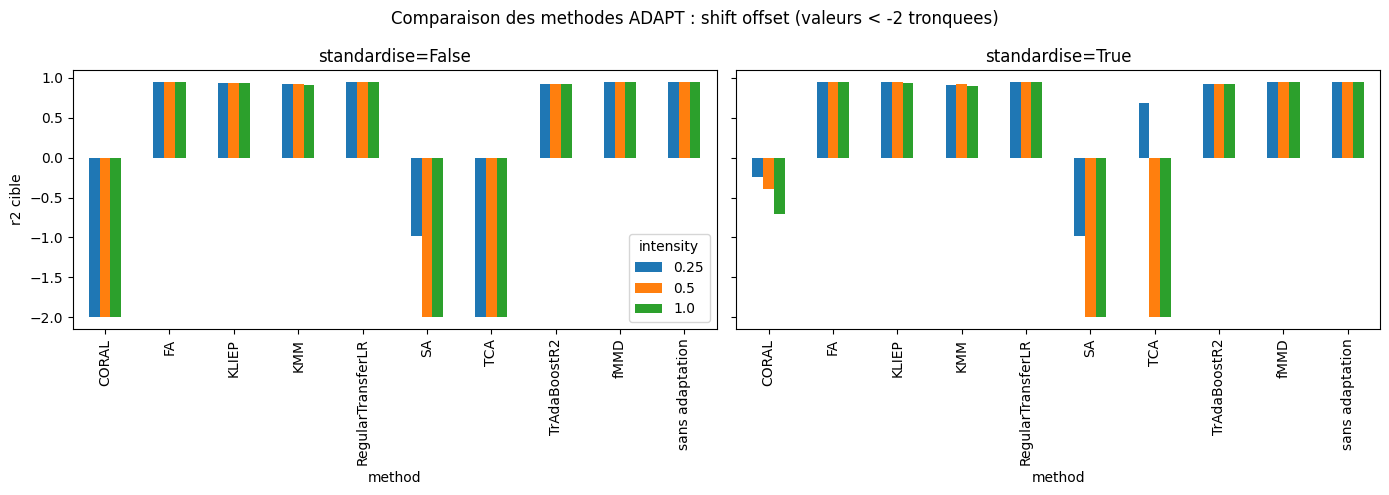

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                      r2_target              \
intensity              0.25       0.50      1.00      0.25        0.50   
method                                                                   
CORAL              0.951031   0.951031  0.951031 -2.686523   -2.938692   
FA                 0.951018   0.951013  0.951005  0.945879    0.945886   
KLIEP              0.944501   0.942759  0.938461  0.939556    0.937441   
KMM                0.932087   0.931968  0.929351  0.922484    0.921627   
RegularTransferLR  0.948029   0.948053  0.948096  0.945980    0.945980   
SA                 0.951031   0.951031  0.951031 -0.988581   -2.013374   
TCA               -4.422217 -49.238550 -2.184185 -6.770066 -111.341917   
TrAdaBoostR2       0.928249   0.928410  0.928714  0.921636    0.921648   
fMMD               0.950386   0.950386  0.950386  0.942973    0.942922   
sans adaptation    0.951031   0.951031  0.951031  0.944470    0.944438   

                              
intensity               1.00  
method                        
CORAL              -3.468571  
FA                  0.945900  
KLIEP               0.931162  
KMM                 0.913381  
RegularTransferLR   0.945979  
SA                 -4.714291  
TCA               -17.579019  
TrAdaBoostR2        0.921658  
fMMD                0.942812  
sans adaptation     0.944369

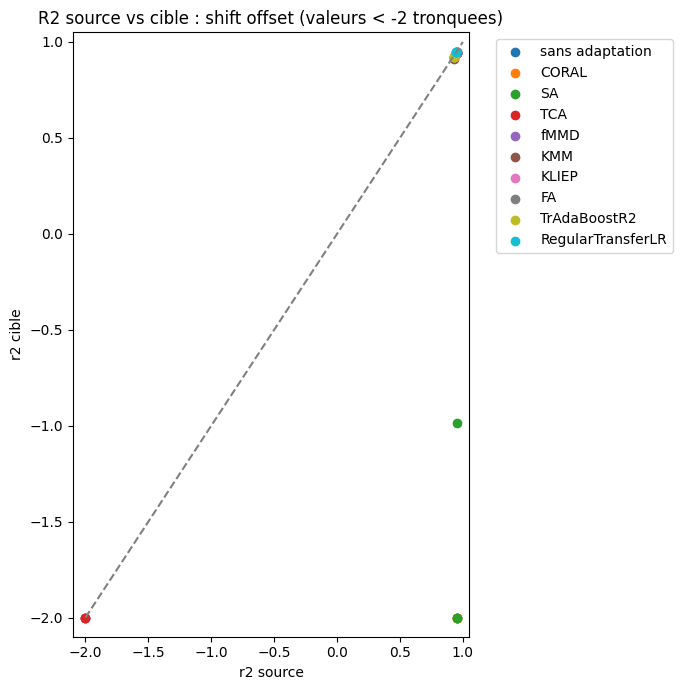

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()